# Actual model comparison plots and predicted-route maps

Use only registry entries marked `trained` whose saved shared-schema model, fold metrics, student-test metrics and predictions exist. A pilot is not a final model. These figures show **currently available trained models**, not proof that all five algorithms are complete.

The maps are offline report artifacts, separate from Claude's frontend/API work. They may show supplied reference routes for comparison. Predicted segments come from actual saved candidate scores; each arc is drawn independently, so no artificial line bridges a jump.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import folium

registry = json.loads(Path("models/registry.json").read_text())
feature_columns = json.loads(Path(registry["feature_columns_path"]).read_text())
output = Path("outputs/maps")
output.mkdir(parents=True, exist_ok=True)
audit = Path("outputs/inventory")
audit.mkdir(parents=True, exist_ok=True)
records, included, skipped = [], {}, {}
for name, entry in registry["models"].items():
    if entry.get("status") != "trained":
        skipped[name] = entry.get("status", "not trained")
        continue
    model_path = Path(entry["model_path"])
    metrics_path = Path(entry["metrics_path"])
    predictions_path = Path(entry["student_test_scores_path"])
    cv_path = metrics_path.parent / "cv_metrics.csv"
    summary_path = metrics_path.parent / "summary.json"
    if summary_path.exists() and json.loads(summary_path.read_text()).get("run_mode") == "pilot":
        skipped[name] = "pilot output is not a final-model experiment"
        continue
    paths = [model_path, metrics_path, predictions_path, cv_path, Path(entry["feature_columns_path"])]
    if not all(path.exists() for path in paths):
        skipped[name] = "required trained-model artifact is missing"
        continue
    if json.loads(Path(entry["feature_columns_path"]).read_text()) != feature_columns:
        skipped[name] = "predictor schema differs from active shared schema"
        continue
    metrics = json.loads(metrics_path.read_text())
    cv = pd.read_csv(cv_path)
    assert len(cv) == 5 and cv["fold"].nunique() == 5
    assert len(metrics["confusion_matrix"]) == 2
    records.append({"model": name, "feature_version": registry["feature_version"],
        "cv_macro_f1_mean": cv["macro_f1"].mean(), "cv_macro_f1_std": cv["macro_f1"].std(),
        "student_top1": metrics["top1"], "student_macro_f1": metrics["macro_f1"],
        "student_log_loss": metrics["log_loss"]})
    included[name] = {"metrics": metrics, "predictions_path": predictions_path}
assert records, "No complete trained shared-model artifacts are ready."
comparison = pd.DataFrame(records)
comparison.to_csv(audit / "model_plot_metrics.csv", index=False)
(audit / "model_visualization_status.json").write_text(json.dumps({
    "feature_version": registry["feature_version"], "included": list(included), "skipped": skipped,
    "scope": "available trained shared models only; not a completed five-model comparison"}, indent=2) + "\n")
display(comparison)
print("Skipped:", skipped)

,model,feature_version,cv_macro_f1_mean,cv_macro_f1_std,student_top1,student_macro_f1,student_log_loss
0,xgboost,direction_32,0.951192,0.018396,0.898904,0.948622,0.276072
1,decision_tree,direction_32,0.938298,0.019404,0.871816,0.934856,0.827966


Skipped: {'logistic_regression': 'awaiting_user_files', 'knn': 'awaiting_final_user_files_existing_notebook_is_pilot', 'stacking': 'awaiting_four_base_OOF_and_final_models'}


## Comparison figures from saved metrics

CV error bars show the sample standard deviation of the five saved folds, not confidence intervals. Student-test log loss uses the shared conditional-on-coverage definition. No artificial training/validation loss curves are created.

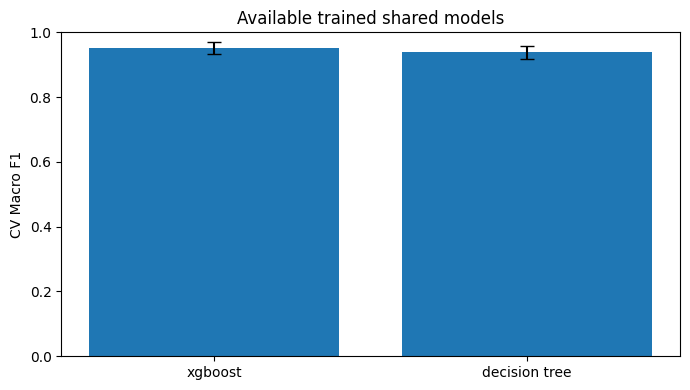

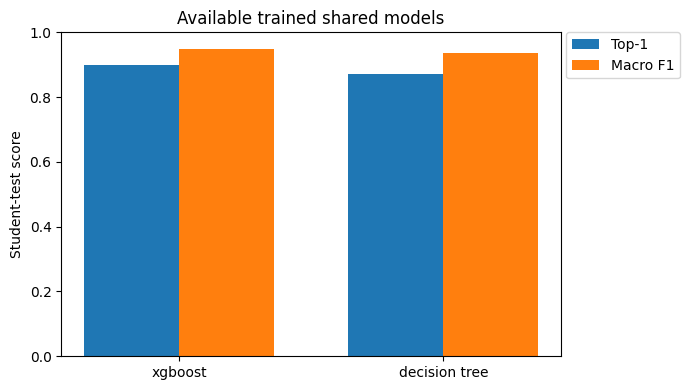

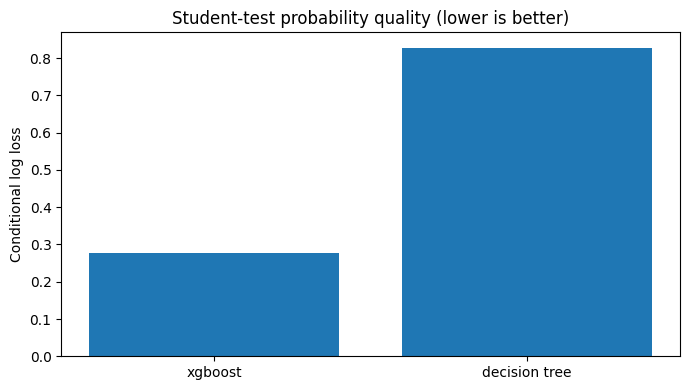

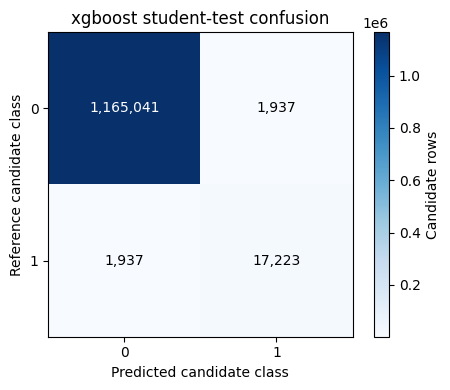

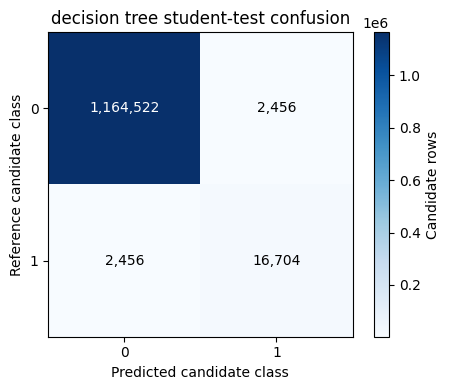

In [2]:
labels = comparison["model"].str.replace("_", " ")
x = np.arange(len(comparison))
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(x, comparison["cv_macro_f1_mean"], yerr=comparison["cv_macro_f1_std"], capsize=5)
ax.set(xticks=x, xticklabels=labels, ylabel="CV Macro F1", ylim=(0, 1), title="Available trained shared models")
fig.tight_layout()
fig.savefig(output / "model_cv_macro_f1.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(x - 0.18, comparison["student_top1"], width=0.36, label="Top-1")
ax.bar(x + 0.18, comparison["student_macro_f1"], width=0.36, label="Macro F1")
ax.set(xticks=x, xticklabels=labels, ylabel="Student-test score", ylim=(0, 1), title="Available trained shared models")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)
fig.tight_layout()
fig.savefig(output / "model_student_test_scores.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(x, comparison["student_log_loss"])
ax.set(xticks=x, xticklabels=labels, ylabel="Conditional log loss", title="Student-test probability quality (lower is better)")
fig.tight_layout()
fig.savefig(output / "model_log_loss.png", dpi=150)
plt.show()

for name, item in included.items():
    matrix = np.asarray(item["metrics"]["confusion_matrix"], dtype=int)
    assert matrix.shape == (2, 2)
    fig, ax = plt.subplots(figsize=(5, 4))
    image = ax.imshow(matrix, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{matrix[i, j]:,}", ha="center", va="center",
                    color="white" if matrix[i, j] > matrix.max() / 2 else "black")
    ax.set(xticks=[0, 1], yticks=[0, 1], xlabel="Predicted candidate class", ylabel="Reference candidate class",
           title=name.replace("_", " ") + " student-test confusion")
    fig.colorbar(image, ax=ax, label="Candidate rows")
    fig.tight_layout()
    fig.savefig(output / f"model_confusion_{name}.png", dpi=150)
    plt.show()

## Layered observed, reference and predicted routes

Use representative small student-test trip `00000052` (262 GPS observations). Model ties choose the lowest segment ID, matching the shared scoring rule. Gray roads show the GPS bounding box with a margin; blue predictions and green supplied reference segments are drawn individually. Red GPS points with no available candidate prediction are black instead.

Each trained model gets its own HTML map, so adding a newly validated registry model and rerunning this notebook updates both plots and maps. The layer control gives the colour legend and allows direct GPS/reference/prediction comparison.

In [3]:
trip_id = "00000052"
folder = Path("Student folder/student_test") / trip_id
nodes = pd.read_csv(folder / f"{trip_id}.nodes", sep=r"\s+", header=None, names=["lon", "lat"])
arcs = pd.read_csv(folder / f"{trip_id}.arcs", sep=r"\s+", header=None).to_numpy()
track = pd.read_csv(folder / f"{trip_id}.track", sep=r"\s+", header=None, names=["lon", "lat", "time"])
route = pd.read_csv(folder / f"{trip_id}.route", sep=r"\s+", header=None)[0].to_numpy()
metadata = pd.read_csv("outputs/student_test/points.csv", dtype={"trip_id": str})
metadata = metadata[metadata["trip_id"] == trip_id][["group_id", "point_id"]]
coordinates = nodes[["lat", "lon"]].to_numpy()
road_xy = nodes[["lon", "lat"]].to_numpy()[arcs]
nearby = (road_xy[:, :, 0].max(axis=1) >= track["lon"].min() - 0.005)
nearby &= road_xy[:, :, 0].min(axis=1) <= track["lon"].max() + 0.005
nearby &= road_xy[:, :, 1].max(axis=1) >= track["lat"].min() - 0.005
nearby &= road_xy[:, :, 1].min(axis=1) <= track["lat"].max() + 0.005
map_rows = []
for name, item in included.items():
    scores = pd.read_csv(item["predictions_path"], usecols=["group_id", "segment_id", "score"])
    scores = scores[scores["group_id"].isin(metadata["group_id"])]
    scores = scores.sort_values(["group_id", "segment_id"]).reset_index(drop=True)
    winners = scores.loc[scores.groupby("group_id")["score"].idxmax()]
    winners = metadata.merge(winners, on="group_id", how="left", validate="one_to_one")
    map_rows.append(winners.assign(model=name, trip_id=trip_id))
    selected = winners["segment_id"].dropna().to_numpy(dtype=int)
    assert ((selected >= 0) & (selected < len(arcs))).all()
    trip_map = folium.Map(location=[track["lat"].mean(), track["lon"].mean()], zoom_start=14)
    road_layer = folium.FeatureGroup(name="Roads (gray)").add_to(trip_map)
    folium.PolyLine(coordinates[arcs[nearby]].tolist(), color="gray", weight=1, opacity=0.6).add_to(road_layer)
    reference_layer = folium.FeatureGroup(name="Supplied reference segments (green)").add_to(trip_map)
    folium.PolyLine(coordinates[arcs[route]].tolist(), color="green", weight=5, opacity=0.65).add_to(reference_layer)
    prediction_layer = folium.FeatureGroup(name=f"{name} predicted segments (blue)").add_to(trip_map)
    folium.PolyLine(coordinates[arcs[selected]].tolist(), color="blue", weight=3, opacity=0.9).add_to(prediction_layer)
    gps_layer = folium.FeatureGroup(name="GPS points (red; black = no prediction)").add_to(trip_map)
    available = set(winners.loc[winners["segment_id"].notna(), "point_id"])
    for point in track.itertuples():
        color = "red" if point.Index in available else "black"
        folium.CircleMarker([point.lat, point.lon], radius=2.5, color=color, fill=True,
                            tooltip=f"GPS point {point.Index} | time {point.time:g} s").add_to(gps_layer)
    folium.LayerControl(collapsed=False).add_to(trip_map)
    trip_map.fit_bounds([[track["lat"].min(), track["lon"].min()], [track["lat"].max(), track["lon"].max()]])
    trip_map.save(output / f"model_{name}_{trip_id}.html")
    print("Saved predicted-route map:", name, trip_id, "| GPS observations:", len(track), flush=True)
pd.concat(map_rows, ignore_index=True).to_csv(audit / "map_prediction_rows.csv", index=False)

Saved predicted-route map: xgboost 00000052 | GPS observations: 262


Saved predicted-route map: decision_tree 00000052 | GPS observations: 262
